# Task: Fraud Detection Using Machine Learning
## Scenario: A financial platform is experiencing suspicious transactions.

## Requirements:
### 1.Create or obtain an imbalanced transaction dataset.
### 2.Perform exploratory data analysis.
### 3.Build at least two fraud detection models.
### 4.Compare precision, recall, F1-score and PR-AUC.
### 5.Address class imbalance without data leakage.
### 6.Explain false positives and false negatives.
### 7.Challenge: Test the model on unseen transactions and explain how it handles suspicious patterns it has never encountered.


### 1.Create or obtain an imbalanced transaction dataset.

In [4]:
# importing necessary libraries

import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
# Dataset path
file_path = "../dataset/creditcard.csv"

# Load dataset
df = pd.read_csv(file_path)

In [6]:
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [7]:
# Display first five records
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [8]:
# Dataset dimensions
df.shape

(284807, 31)

In [9]:
# Total transactions
print("Total Transactions:", len(df))

Total Transactions: 284807


In [10]:
# Class distribution
print("\nTransaction Distribution:")
print(df["Class"].value_counts())


Transaction Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


##### In above code snippet 
##### 0 means normal transactions ( so 284315 normal transactions)
##### 1 means fraud transactions ( 492 fraud transactions)

In [12]:
# Fraud percentage
fraud_percentage = (df["Class"].sum() / len(df)) * 100
print("\nFraud Percentage:", fraud_percentage, "%")


Fraud Percentage: 0.1727485630620034 %


### 2.Perform exploratory data analysis.

In [14]:
# Check data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [15]:
# statistical properties of all columns
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [16]:
# To include all numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [17]:
# Check missing values
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [18]:
# Total missing values
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [19]:
# Check duplicate transactions

In [20]:
# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 1081


In [21]:
# Here, i am not removing the duplicate values because it became very highly imbalance data 
# so that, it only works well on detecting normal transactions instead also on fraud 
# so, i am keeping the entire dataset as it is 

In [22]:
# Count normal and fraudulent transactions
class_counts = df["Class"].value_counts()

print("Transaction Class Distribution:")
print(class_counts)

Transaction Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


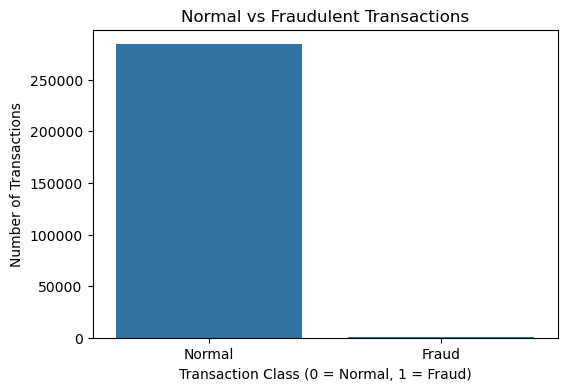

In [23]:
# Visualize transaction distribution using a count plot
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Class")

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ["Normal", "Fraud"])

plt.show()

In [24]:
# Statistical analysis of transaction amounts

print("Transaction Amount Statistics:")
df["Amount"].describe()

Transaction Amount Statistics:


count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

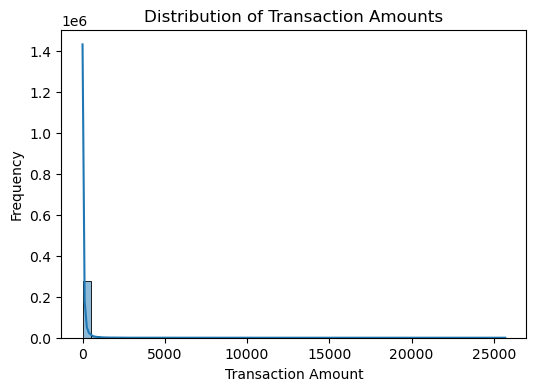

In [25]:
# Distribution of transaction amounts
plt.figure(figsize=(6, 4))

sns.histplot(
    df["Amount"],
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

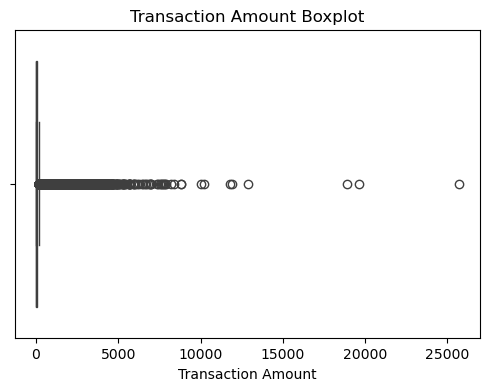

In [26]:
# Boxplot of transaction amounts

plt.figure(figsize=(6, 4))

sns.boxplot(x=df["Amount"])

plt.title("Transaction Amount Boxplot")
plt.xlabel("Transaction Amount")

plt.show()

In [27]:
# Time statistics
print(df["Time"].describe())

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64


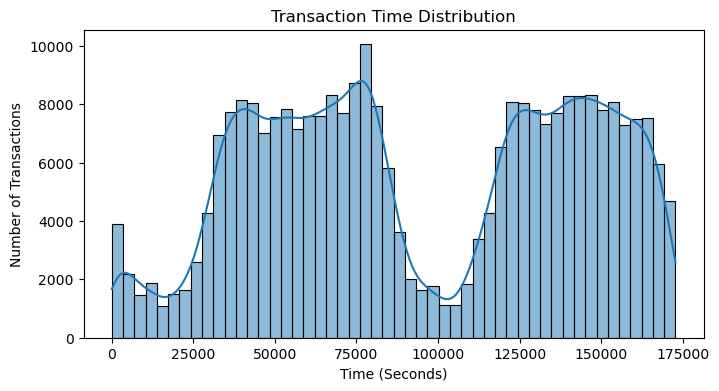

In [28]:
# Distribution of transaction time

plt.figure(figsize=(8, 4))

sns.histplot(
    df["Time"],
    bins=50,
    kde=True
)

plt.title("Transaction Time Distribution")
plt.xlabel("Time (Seconds)")
plt.ylabel("Number of Transactions")

plt.show()

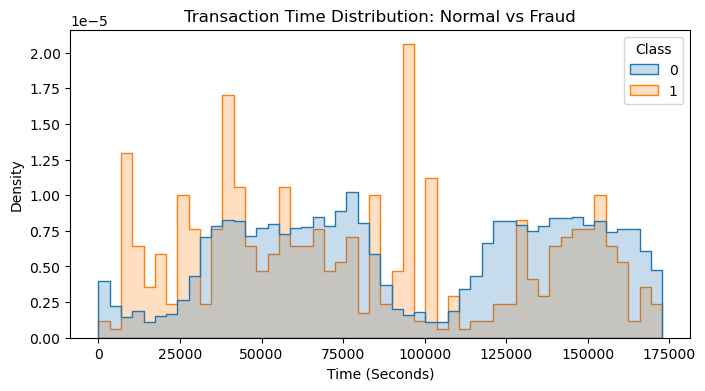

In [29]:
# Compare transaction time by class

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Time Distribution: Normal vs Fraud")
plt.xlabel("Time (Seconds)")
plt.ylabel("Density")

plt.show()

In [30]:
# Calculate feature means by class

feature_means = df.groupby("Class").mean(numeric_only=True).T
print(feature_means)

Class              0             1
Time    94838.202258  80746.806911
V1          0.008258     -4.771948
V2         -0.006271      3.623778
V3          0.012171     -7.033281
V4         -0.007860      4.542029
V5          0.005453     -3.151225
V6          0.002419     -1.397737
V7          0.009637     -5.568731
V8         -0.000987      0.570636
V9          0.004467     -2.581123
V10         0.009824     -5.676883
V11        -0.006576      3.800173
V12         0.010832     -6.259393
V13         0.000189     -0.109334
V14         0.012064     -6.971723
V15         0.000161     -0.092929
V16         0.007164     -4.139946
V17         0.011535     -6.665836
V18         0.003887     -2.246308
V19        -0.001178      0.680659
V20        -0.000644      0.372319
V21        -0.001235      0.713588
V22        -0.000024      0.014049
V23         0.000070     -0.040308
V24         0.000182     -0.105130
V25        -0.000072      0.041449
V26        -0.000089      0.051648
V27        -0.000295

<Figure size 800x600 with 0 Axes>

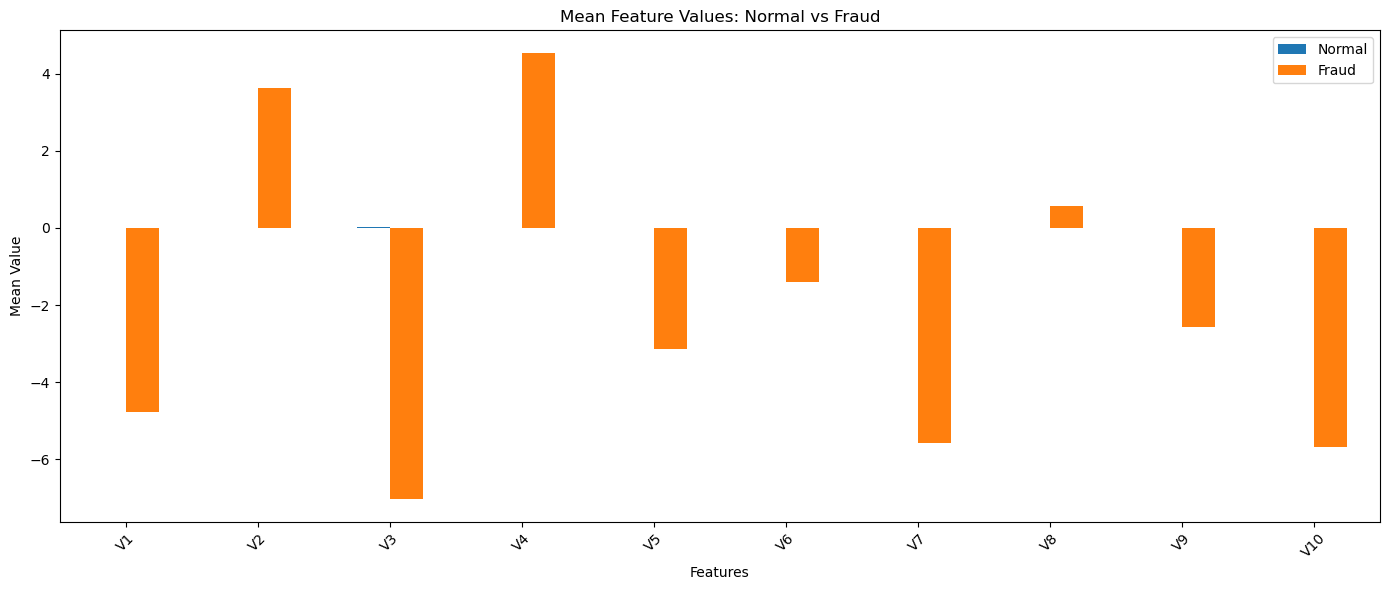

In [31]:
# Compare feature means for V1 to V10
features = [f"V{i}" for i in range(1, 11)]

plt.figure(figsize=(8, 6))

feature_means.loc[features].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Mean Feature Values: Normal vs Fraud")
plt.xlabel("Features")
plt.ylabel("Mean Value")

plt.xticks(rotation=45)
plt.legend(["Normal", "Fraud"])

plt.tight_layout()
plt.show()

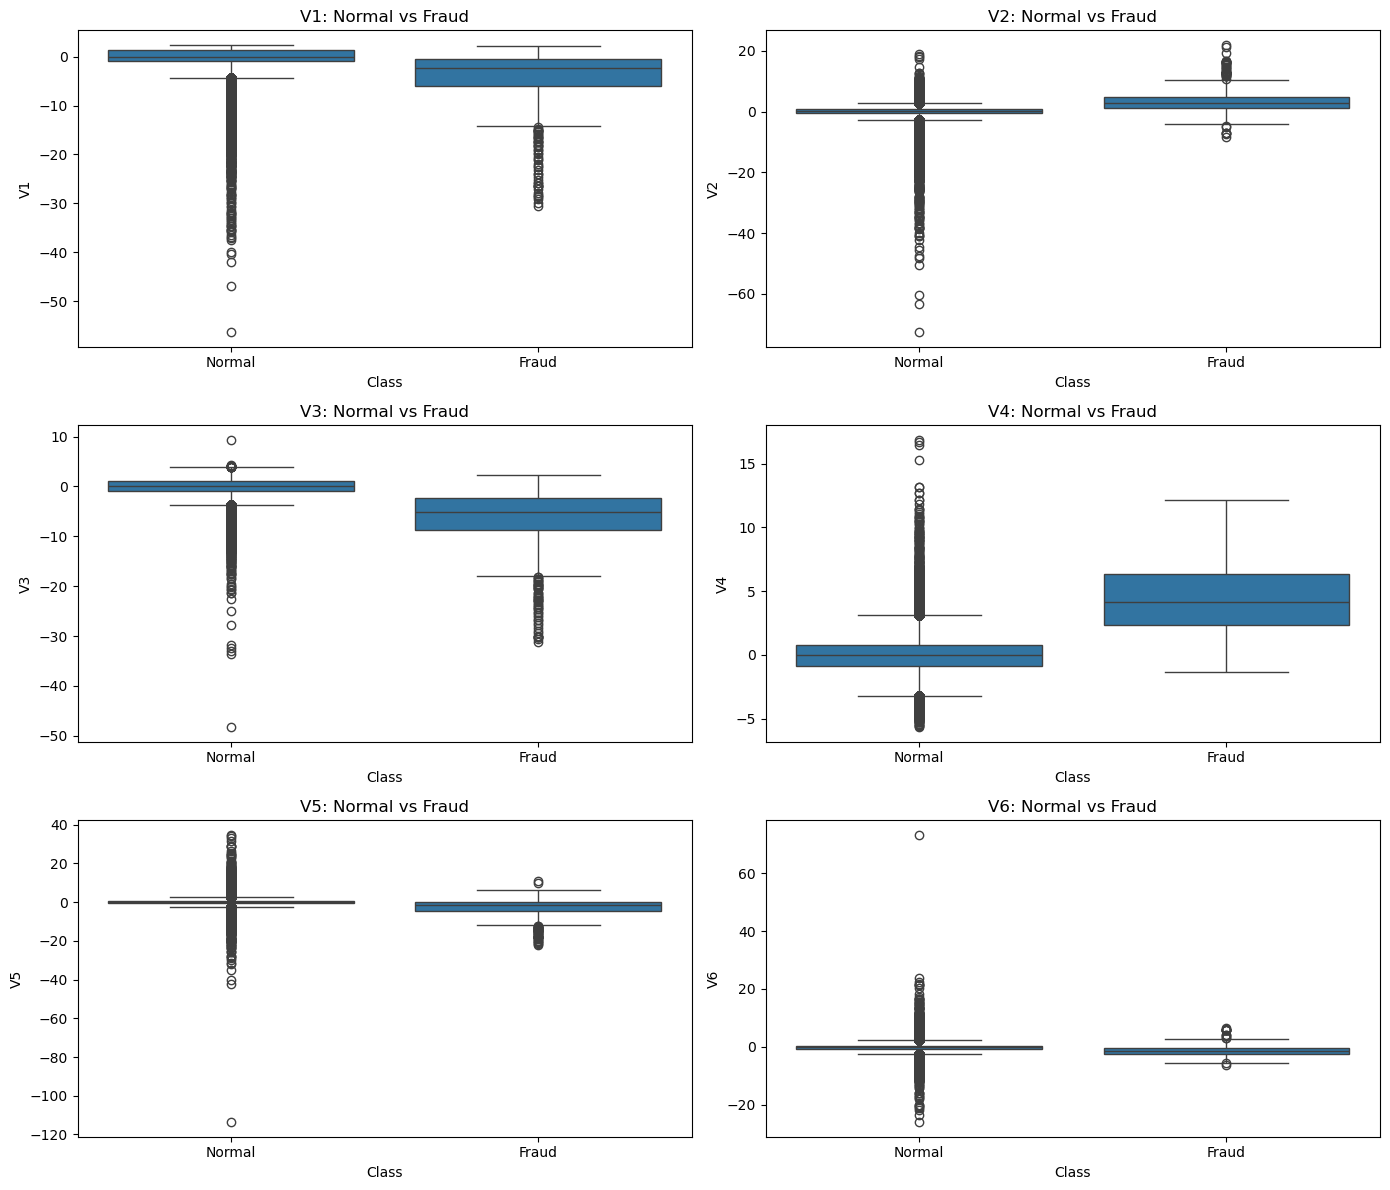

In [32]:
# Visualize selected feature distributions
selected_features = ["V1", "V2", "V3", "V4", "V5", "V6"]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for feature, ax in zip(selected_features, axes.flatten()):

    sns.boxplot(
        data=df,
        x="Class",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature}: Normal vs Fraud")
    ax.set_xticks([0, 1], labels=["Normal", "Fraud"])
    
plt.tight_layout()
plt.show()

In [33]:
# Correlation analysis
correlation_matrix = df.corr()

print(correlation_matrix)

            Time            V1            V2            V3            V4  \
Time    1.000000  1.173963e-01 -1.059333e-02 -4.196182e-01 -1.052602e-01   
V1      0.117396  1.000000e+00  4.135835e-16 -1.227819e-15 -9.215150e-16   
V2     -0.010593  4.135835e-16  1.000000e+00  3.243764e-16 -1.121065e-15   
V3     -0.419618 -1.227819e-15  3.243764e-16  1.000000e+00  4.711293e-16   
V4     -0.105260 -9.215150e-16 -1.121065e-15  4.711293e-16  1.000000e+00   
V5      0.173072  1.812612e-17  5.157519e-16 -6.539009e-17 -1.719944e-15   
V6     -0.063016 -6.506567e-16  2.787346e-16  1.627627e-15 -7.491959e-16   
V7      0.084714 -1.005191e-15  2.055934e-16  4.895305e-16 -4.104503e-16   
V8     -0.036949 -2.433822e-16 -5.377041e-17 -1.268779e-15  5.697192e-16   
V9     -0.008660 -1.513678e-16  1.978488e-17  5.568367e-16  6.923247e-16   
V10     0.030617  7.388135e-17 -3.991394e-16  1.156587e-15  2.232685e-16   
V11    -0.247689  2.125498e-16  1.975426e-16  1.576830e-15  3.459380e-16   
V12     0.12

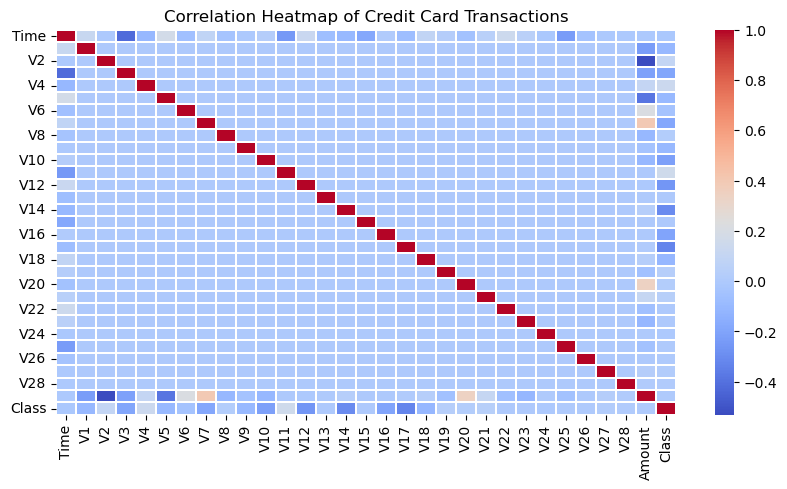

In [34]:
# Visualize correlation heatmap
plt.figure(figsize=(10, 5))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Credit Card Transactions")

plt.show()

In [35]:
# Identify features most correlated with fraud
fraud_correlation = (
    correlation_matrix["Class"]
    .drop("Class")
    .sort_values(ascending=False)
)

print("Feature Correlation with Fraud:")
print(fraud_correlation)

Feature Correlation with Fraud:
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
Time     -0.012323
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


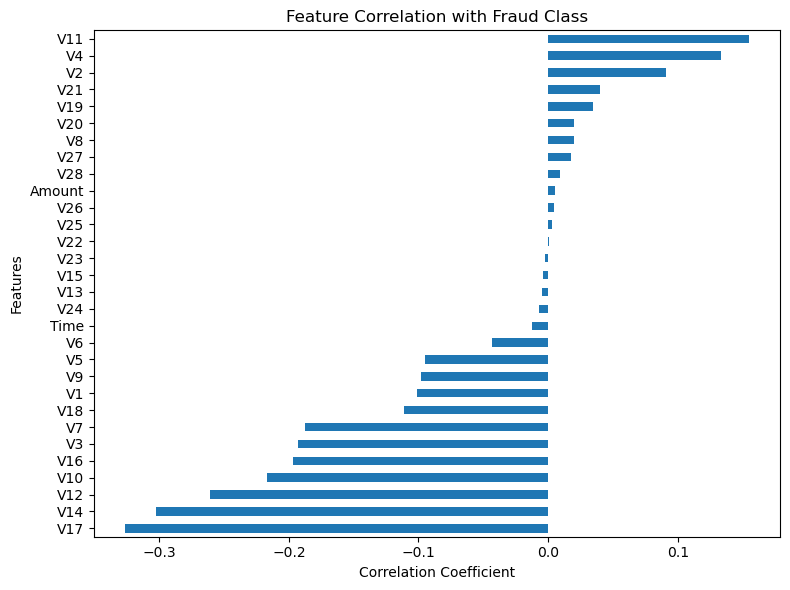

In [36]:
# Visualize feature correlation with Class
plt.figure(figsize=(8, 6))

fraud_correlation.sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlation with Fraud Class")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [37]:
# Compare normal and fraudulent transaction statistics
comparison = df.groupby("Class").agg({
    "Amount": ["count", "mean", "median", "min", "max", "std"],
    "Time": ["mean", "median", "min", "max"]
})

comparison.index = ["Normal", "Fraud"]

print(comparison)

        Amount                                                        Time  \
         count        mean median  min       max         std          mean   
Normal  284315   88.291022  22.00  0.0  25691.16  250.105092  94838.202258   
Fraud      492  122.211321   9.25  0.0   2125.87  256.683288  80746.806911   

                                  
         median    min       max  
Normal  84711.0    0.0  172792.0  
Fraud   75568.5  406.0  170348.0  


### 3.Build at least two fraud detection models.

In [39]:
pip install pandas numpy scikit-learn xgboost matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import time

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.ensemble import (
    RandomForestClassifier,
    IsolationForest
)

from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve
)

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [41]:
# creating input and target variables 

X = df.drop("Class", axis=1)
y = df["Class"]

In [42]:
X.shape

(284807, 30)

In [43]:
y.shape

(284807,)

In [44]:
# Split the dataset

  #70% training data
  #15% validation data
  #15% testing data

In [45]:
# First split
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nFraud cases:")

print("Training:", y_train.sum())
print("Validation:", y_val.sum())
print("Testing:", y_test.sum())

Training: (199364, 30)
Validation: (42721, 30)
Testing: (42722, 30)

Fraud cases:
Training: 344
Validation: 74
Testing: 74


In [46]:
# Calculate class imbalance weight
normal_count = (y_train == 0).sum()
fraud_count = (y_train == 1).sum()

class_weight_ratio = normal_count / fraud_count

print("Normal Transactions:", normal_count)
print("Fraud Transactions:", fraud_count)

print("Class Weight Ratio:", class_weight_ratio)

Normal Transactions: 199020
Fraud Transactions: 344
Class Weight Ratio: 578.546511627907


##### Imputing Random Forest with Class Weights
##### Random Forest builds multiple decision trees and combines their predictions.

In [48]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    max_features="sqrt"
)

start_time = time.time()

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")
print("Training Time:", round(time.time() - start_time, 2), "seconds")

Random Forest Training Completed!
Training Time: 523.02 seconds


In [49]:
# Generate validation probabilities
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

In [50]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict
rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

# Accuracy
rf_train_accuracy = accuracy_score(y_train, rf_train_pred)
rf_test_accuracy = accuracy_score(y_test, rf_test_pred)

print("========== RANDOM FOREST ==========")
print("Training Accuracy:", round(rf_train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(rf_test_accuracy * 100, 2), "%")

========== RANDOM FOREST ==========
Training Accuracy: 100.0 %
Testing Accuracy: 99.95 %


In [51]:
# Find the optimal threshold
def find_best_threshold(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_index = np.argmax(f1_scores)

    return thresholds[best_index], f1_scores[best_index]


rf_threshold, rf_val_f1 = find_best_threshold(
    y_val,
    rf_val_prob
)

print("Random Forest Threshold:", rf_threshold)
print("Random Forest Validation F1:", rf_val_f1)

Random Forest Threshold: 0.36666666666666664
Random Forest Validation F1: 0.8270676691235682


In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Random Forest Predictions
y_pred = rf_model.predict(X_test)

print("\n========== RANDOM FOREST ==========")

# Evaluation Metrics
print("Accuracy:",
      accuracy_score(y_test, y_pred) * 100, "%")

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))


# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))


========== RANDOM FOREST ==========
Accuracy: 99.9461635691213 %
Precision: 0.9636363636363636
Recall: 0.7162162162162162
F1 Score: 0.8217054263565892

Confusion Matrix:
[[42646     2]
 [   21    53]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     42648
       Fraud       0.96      0.72      0.82        74

    accuracy                           1.00     42722
   macro avg       0.98      0.86      0.91     42722
weighted avg       1.00      1.00      1.00     42722



##### XGBoost with Class Weights
##### XGBoost is a gradient boosting algorithm. 
##### It builds trees sequentially and attempts to improve predictions by correcting previous errors.

In [54]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=class_weight_ratio,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

xgb_model.fit(X_train, y_train)

print("XGBoost Training Completed!")
print("Training Time:", round(time.time() - start_time, 2), "seconds")

XGBoost Training Completed!
Training Time: 19.34 seconds


In [55]:
# Generate validation probabilities
xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]

xgb_threshold, xgb_val_f1 = find_best_threshold(
    y_val,
    xgb_val_prob
)

print("XGBoost Threshold:", xgb_threshold)
print("XGBoost Validation F1:", xgb_val_f1)

XGBoost Threshold: 0.9435531
XGBoost Validation F1: 0.8358208954729338


In [56]:
# Predict
xgb_train_pred = xgb_model.predict(X_train)
xgb_test_pred = xgb_model.predict(X_test)

# Accuracy
xgb_train_accuracy = accuracy_score(y_train, xgb_train_pred)
xgb_test_accuracy = accuracy_score(y_test, xgb_test_pred)

print("========== XGBOOST ==========")
print("Training Accuracy:", round(xgb_train_accuracy * 100, 2), "%")
print("Testing Accuracy:", round(xgb_test_accuracy * 100, 2), "%")

========== XGBOOST ==========
Training Accuracy: 99.98 %
Testing Accuracy: 99.94 %


In [57]:
# XGBoost threshold optimization
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Get fraud probabilities from validation data
y_val_prob = xgb_model.predict_proba(X_val)[:, 1]

# Test different thresholds
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(
        y_val, y_val_pred, zero_division=0
    )

    recall = recall_score(
        y_val, y_val_pred, zero_division=0
    )

    f1 = f1_score(
        y_val, y_val_pred, zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

   Threshold  Precision  Recall  F1 Score
0        0.2     0.6019  0.8378    0.7006
1        0.3     0.6739  0.8378    0.7470
2        0.4     0.7059  0.8108    0.7547
3        0.5     0.7532  0.7838    0.7682
4        0.6     0.7917  0.7703    0.7808
5        0.7     0.8028  0.7703    0.7862


In [58]:
# Fine-tune the threshold
fine_thresholds = np.arange(0.60, 0.81, 0.02)

fine_results = []

for threshold in fine_thresholds:

    y_val_pred = (
        xgb_model.predict_proba(X_val)[:, 1] >= threshold
    ).astype(int)

    fine_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_val_pred, zero_division=0
        )
    })

fine_results_df = pd.DataFrame(fine_results)

print(fine_results_df.round(4))

best_threshold = fine_results_df.loc[
    fine_results_df["F1 Score"].idxmax(),
    "Threshold"
]

print("\nBest Validation Threshold:", best_threshold)

    Threshold  Precision  Recall  F1 Score
0        0.60     0.7917  0.7703    0.7808
1        0.62     0.7917  0.7703    0.7808
2        0.64     0.7917  0.7703    0.7808
3        0.66     0.7917  0.7703    0.7808
4        0.68     0.7917  0.7703    0.7808
5        0.70     0.8028  0.7703    0.7862
6        0.72     0.8143  0.7703    0.7917
7        0.74     0.8261  0.7703    0.7972
8        0.76     0.8507  0.7703    0.8085
9        0.78     0.8507  0.7703    0.8085
10       0.80     0.8769  0.7703    0.8201

Best Validation Threshold: 0.8


In [59]:
best_xgb_threshold = 0.80

print("Selected XGBoost Threshold:",
      best_xgb_threshold)

Selected XGBoost Threshold: 0.8


In [60]:
# Evaluate on the untouched test dataset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Predict fraud probabilities
y_test_prob = xgb_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
y_test_pred = (
    y_test_prob >= best_xgb_threshold
).astype(int)

print("========== XGBOOST FINAL TEST RESULTS ==========")

print("Threshold:", best_xgb_threshold)

print("Accuracy:",
      accuracy_score(y_test, y_test_pred) * 100)

print("Precision:",
      precision_score(y_test, y_test_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_test_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_test_pred, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_test_prob))

print("PR-AUC:",
      average_precision_score(y_test, y_test_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

========== XGBOOST FINAL TEST RESULTS ==========
Threshold: 0.8
Accuracy: 99.94850428350732
Precision: 0.8823529411764706
Recall: 0.8108108108108109
F1 Score: 0.8450704225352113
ROC-AUC: 0.968691855896414
PR-AUC: 0.8340055670170115

Confusion Matrix:
[[42640     8]
 [   14    60]]

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     42648
       Fraud       0.88      0.81      0.85        74

    accuracy                           1.00     42722
   macro avg       0.94      0.91      0.92     42722
weighted avg       1.00      1.00      1.00     42722



##### Anomaly Detection
##### Unlike Random Forest and XGBoost, 
##### anomaly detection algorithms identify unusual transactions based on their patterns.

In [62]:
# Prepare normal training transactions
# First, standardize the features for anomaly detection.
from sklearn.preprocessing import StandardScaler

# Keep only normal transactions for anomaly training
X_train_normal = X_train[y_train == 0].copy()

print("Normal Training Transactions:", X_train_normal.shape)

# Fit scaler only on normal training transactions
scaler = StandardScaler()

X_train_normal_scaled = scaler.fit_transform(X_train_normal)

X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Anomaly detection data prepared successfully!")

Normal Training Transactions: (199020, 30)
Anomaly detection data prepared successfully!


##### Isolation Forest
##### Isolation Forest isolates unusual data points using randomly generated decision trees.
##### Fraudulent transactions that are easier to isolate may receive higher anomaly scores.

In [64]:
# Train Isolation Forest
if_model = IsolationForest(
    n_estimators=300,
    max_samples="auto",
    contamination="auto",
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

if_model.fit(X_train_normal_scaled)

print("Isolation Forest Training Completed!")
print("Training Time:", round(time.time() - start_time, 2), "seconds")

Isolation Forest Training Completed!
Training Time: 3.53 seconds


In [65]:
from sklearn.metrics import accuracy_score

# Predict (-1 = Anomaly, 1 = Normal)
if_train_pred = if_model.predict(X_train_normal_scaled)
if_test_pred = if_model.predict(X_test_scaled)

# Convert predictions
# -1 = Fraud (1)
#  1 = Normal (0)

if_train_pred = (if_train_pred == -1).astype(int)
if_test_pred = (if_test_pred == -1).astype(int)

# Actual labels for normal training data
y_train_normal = y_train[X_train[y_train == 0].index] if hasattr(y_train, "index") else None

In [66]:
if_test_accuracy = accuracy_score(y_test, if_test_pred)

print("========== ISOLATION FOREST ==========")
print("Testing Accuracy:", round(if_test_accuracy * 100, 2), "%")

========== ISOLATION FOREST ==========
Testing Accuracy: 96.37 %


In [67]:
# Generate anomaly scores
if_val_scores = -if_model.score_samples(X_val_scaled)

print("Isolation Forest Validation Scores:")
print(if_val_scores[:10])

Isolation Forest Validation Scores:
[0.36988495 0.42277858 0.42314143 0.42739276 0.36328889 0.38278716
 0.39972764 0.39835544 0.36775699 0.41312447]


In [68]:
# Find the optimal anomaly threshold
if_threshold, if_val_f1 = find_best_threshold(
    y_val,
    if_val_scores
)

if_val_pred = (
    if_val_scores >= if_threshold
).astype(int)

print("Isolation Forest Threshold:", if_threshold)
print("Isolation Forest Validation F1:", if_val_f1)

print("\nValidation Classification Report:")

print(classification_report(
    y_val,
    if_val_pred,
    target_names=["Normal", "Fraud"],
    zero_division=0
))

Isolation Forest Threshold: 0.652719414146064
Isolation Forest Validation F1: 0.23529411759711222

Validation Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     42647
       Fraud       0.23      0.24      0.24        74

    accuracy                           1.00     42721
   macro avg       0.61      0.62      0.62     42721
weighted avg       1.00      1.00      1.00     42721



In [69]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Generate anomaly scores
if_test_scores = -if_model.score_samples(X_test_scaled)

# Evaluate ranking performance
if_roc_auc = roc_auc_score(
    y_test,
    if_test_scores
)

if_pr_auc = average_precision_score(
    y_test,
    if_test_scores
)

print("Isolation Forest ROC-AUC:", if_roc_auc)
print("Isolation Forest PR-AUC:", if_pr_auc)

Isolation Forest ROC-AUC: 0.9473458404944055
Isolation Forest PR-AUC: 0.1275236947118963


### 4.Compare precision, recall, F1-score and PR-AUC.

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Model performance results
results = {
    "Model": [
        "Random Forest",
        "XGBoost",
        "Isolation Forest"
    ],
    "Precision": [0.9636, 0.8824, 0.23],
    "Recall": [0.7162, 0.8108, 0.24],
    "F1 Score": [0.8217, 0.8451, 0.2353],
    "PR-AUC": [0.8169, 0.8340, 0.1275]
}

comparison_df = pd.DataFrame(results)

# Display results in percentage format
display(
    comparison_df.style.format({
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}",
        "PR-AUC": "{:.2%}"
    }).set_caption("Fraud Detection Model Performance Comparison")
)

,Model,Precision,Recall,F1 Score,PR-AUC
0,Random Forest,96.36%,71.62%,82.17%,81.69%
1,XGBoost,88.24%,81.08%,84.51%,83.40%
2,Isolation Forest,23.00%,24.00%,23.53%,12.75%


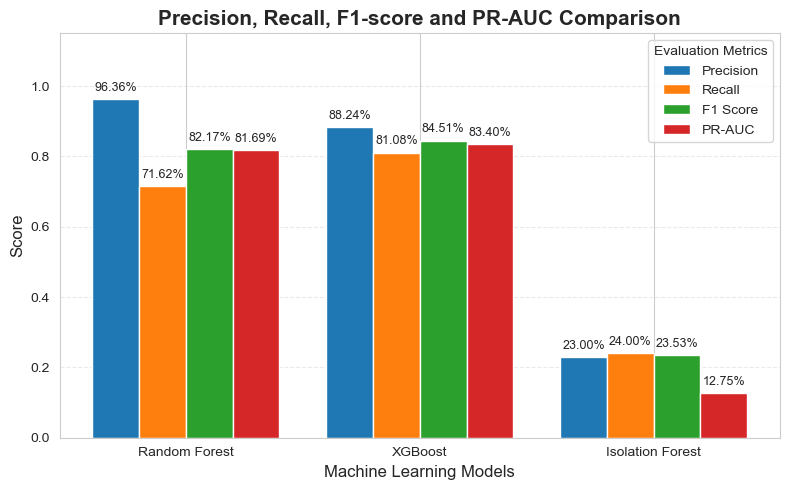

In [72]:
# Metrics for comparison
metrics = ["Precision", "Recall", "F1 Score", "PR-AUC"]

models = comparison_df["Model"]

x = np.arange(len(models))
width = 0.20

plt.figure(figsize=(8, 5))

# Create grouped bars
for i, metric in enumerate(metrics):

    values = comparison_df[metric].values

    bars = plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=metric
    )

    # Display values above bars
    for bar in bars:

        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2%}",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.title(
    "Precision, Recall, F1-score and PR-AUC Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Machine Learning Models", fontsize=12)
plt.ylabel("Score", fontsize=12)

plt.xticks(x, models)
plt.ylim(0, 1.15)

plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 5.Address class imbalance without data leakage.

In [74]:
!pip install imbalanced-learn

In [75]:
import pandas as pd
import numpy as np

from imblearn.over_sampling import SMOTE
from collections import Counter

In [76]:
# Check class distribution before SMOTE
print("Before SMOTE:")

print("Training dataset:", Counter(y_train))
print("Validation dataset:", Counter(y_val))
print("Testing dataset:", Counter(y_test))

Before SMOTE:
Training dataset: Counter({0: 199020, 1: 344})
Validation dataset: Counter({0: 42647, 1: 74})
Testing dataset: Counter({0: 42648, 1: 74})


In [77]:
# Apply SMOTE only to training data
from sklearn.preprocessing import RobustScaler

# Make copies to preserve original datasets
X_train_smote = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Scale Time and Amount using training data only
scaler = RobustScaler()

X_train_smote[["Time", "Amount"]] = scaler.fit_transform(
    X_train_smote[["Time", "Amount"]]
)

X_val_scaled[["Time", "Amount"]] = scaler.transform(
    X_val_scaled[["Time", "Amount"]]
)

X_test_scaled[["Time", "Amount"]] = scaler.transform(
    X_test_scaled[["Time", "Amount"]]
)

# Apply SMOTE ONLY to training data
smote = SMOTE(
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=5
)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_smote,
    y_train
)

print("Before SMOTE:", Counter(y_train))
print("After SMOTE:", Counter(y_train_resampled))

Before SMOTE: Counter({0: 199020, 1: 344})
After SMOTE: Counter({0: 199020, 1: 199020})


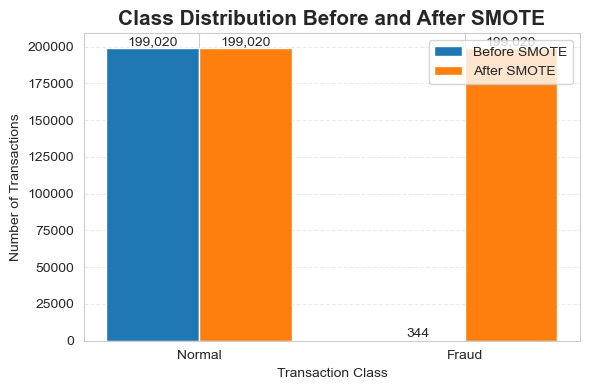

In [78]:
# Visualize class distribution before and after SMOTE
before = Counter(y_train)
after = Counter(y_train_resampled)

labels = ["Normal", "Fraud"]

before_values = [
    before[0],
    before[1]
]

after_values = [
    after[0],
    after[1]
]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(6, 4))

bars1 = plt.bar(
    x - width / 2,
    before_values,
    width,
    label="Before SMOTE"
)

bars2 = plt.bar(
    x + width / 2,
    after_values,
    width,
    label="After SMOTE"
)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height):,}",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.title(
    "Class Distribution Before and After SMOTE",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.xticks(x, labels)
plt.legend()

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [79]:
# Verify that there is no data leakage
print("TRAINING DATA AFTER SMOTE")
print(Counter(y_train_resampled))

print("\nVALIDATION DATA - ORIGINAL")
print(Counter(y_val))

print("\nTESTING DATA - ORIGINAL")
print(Counter(y_test))

print("\nDataset shapes:")
print("X_train_resampled:", X_train_resampled.shape)
print("X_val_scaled:", X_val_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

TRAINING DATA AFTER SMOTE
Counter({0: 199020, 1: 199020})

VALIDATION DATA - ORIGINAL
Counter({0: 42647, 1: 74})

TESTING DATA - ORIGINAL
Counter({0: 42648, 1: 74})

Dataset shapes:
X_train_resampled: (398040, 30)
X_val_scaled: (42721, 30)
X_test_scaled: (42722, 30)


### 6.Explain false positives and false negatives.

# False Positives and False Negatives in Credit Card Fraud Detection
In machine learning, particularly in classification problems, False Positives and False Negatives are two important types of prediction errors.
They help us understand how often a model incorrectly classifies data.

In a credit card fraud detection system, the model classifies each transaction into two categories:
- Normal (0): A legitimate transaction.
- Fraud (1): A fraudulent transaction.
1. False Positive (FP)
A False Positive occurs when the machine learning model incorrectly predicts a normal transaction as fraudulent.

In other words:
- Actual class: Normal
- Predicted class: Fraud
- 
Example:
A customer makes a genuine credit card transaction of ₹5,000. However, the fraud detection system incorrectly identifies it as fraudulent and flags or blocks the transaction.

2. False Negative (FN)
A False Negative occurs when the machine learning model incorrectly predicts a fraudulent transaction as normal.

In other words:
- Actual class: Fraud
- Predicted class: Normal
- 
Example:
A fraudster makes an unauthorized credit card transaction of ₹20,000. However, the fraud detection system incorrectly identifies it as a normal transaction and allows it to pass without raising an alert.

In [82]:
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Extract values
TN, FP, FN, TP = cm.ravel()

print("CONFUSION MATRIX ANALYSIS")
print("-------------------------")

print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)

print("\nINTERPRETATION")

print("False Positives:",
      FP, "normal transactions incorrectly predicted as fraud")

print("False Negatives:",
      FN, "fraud transactions incorrectly predicted as normal")

CONFUSION MATRIX ANALYSIS
-------------------------
True Negative (TN): 42640
False Positive (FP): 8
False Negative (FN): 14
True Positive (TP): 60

INTERPRETATION
False Positives: 8 normal transactions incorrectly predicted as fraud
False Negatives: 14 fraud transactions incorrectly predicted as normal


CONFUSION MATRIX ANALYSIS
-------------------------
True Negative (TN): 42640
False Positive (FP): 8
False Negative (FN): 14
True Positive (TP): 60

INTERPRETATION
False Positives: 8 normal transactions incorrectly predicted as fraud
False Negatives: 14 fraud transactions incorrectly predicted as normal


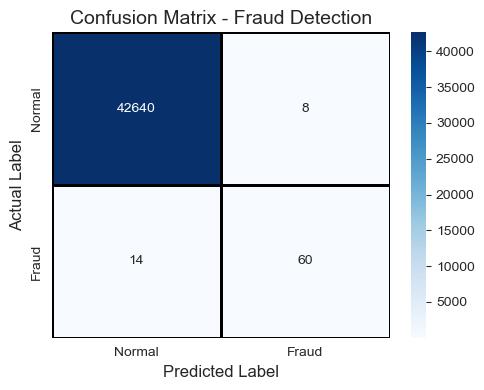

In [217]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_test_pred)

# Extract values
TN, FP, FN, TP = cm.ravel()

print("CONFUSION MATRIX ANALYSIS")
print("-------------------------")

print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)

print("\nINTERPRETATION")

print("False Positives:",
      FP, "normal transactions incorrectly predicted as fraud")

print("False Negatives:",
      FN, "fraud transactions incorrectly predicted as normal")

# Visualize confusion matrix
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Fraud'],
    yticklabels=['Normal', 'Fraud'],
    linewidths=1,
    linecolor='black',
    cbar=True
)

plt.title('Confusion Matrix - Fraud Detection', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)

plt.tight_layout()
plt.show()

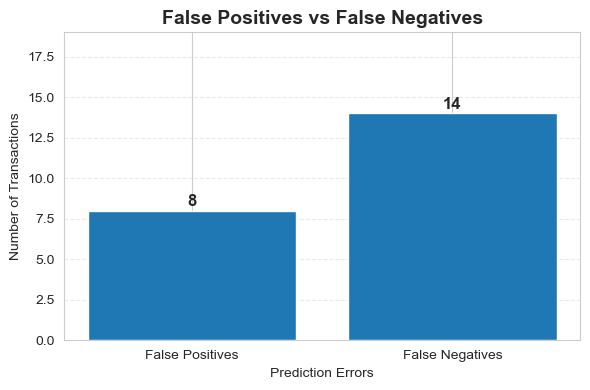

In [84]:
# Visualize False Positives and False Negatives
import matplotlib.pyplot as plt

error_labels = [
    "False Positives",
    "False Negatives"
]

error_values = [FP, FN]

plt.figure(figsize=(6, 4))

bars = plt.bar(error_labels, error_values)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.3,
        str(height),
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title(
    "False Positives vs False Negatives",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Prediction Errors")
plt.ylabel("Number of Transactions")

plt.ylim(0, max(error_values) + 5)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 7. Challenge: Test the model on unseen transactions 
### and explain how it handles suspicious patterns it has never encountered.

In [86]:
# Select unseen transactions
# Using test dataset, which was not used during model training.

unseen_transactions = X_test_scaled.iloc[:10].copy()

print("Unseen Transactions:")
display(unseen_transactions)

Unseen Transactions:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
235888,0.748838,-1.088603,0.227684,1.704464,-2.353332,-0.020576,-0.172107,0.583032,0.061733,0.239969,...,-0.073804,0.217621,0.653238,-0.327775,-0.315684,0.583262,0.743450,-0.120432,0.005165,0.529027
45489,-0.499035,-9.341359,7.462989,-2.710666,-2.250661,-1.917028,-0.948412,0.299620,0.683355,6.816811,...,4.643628,-1.587047,-1.188229,0.213025,-0.194682,1.445639,-0.066416,1.281673,-0.371747,-0.169149
127370,-0.076823,-0.341638,1.096437,1.282236,0.067246,-0.023312,-0.990693,0.687884,-0.046890,-0.323266,...,0.085513,-0.268609,-0.728375,-0.005895,0.320908,-0.176452,0.073411,0.242071,0.097307,-0.238619
49525,-0.478720,-1.440550,1.868637,1.015135,0.570414,0.012212,0.735390,-0.530908,-2.940731,-0.491389,...,-0.553288,3.267467,-0.233295,0.222171,-0.029602,-0.118281,-0.226221,0.573718,0.226211,-0.098844
146811,0.035888,-1.405410,1.985541,-1.290536,-1.672087,1.133642,-1.327069,1.839333,-0.605819,1.243372,...,0.881069,-0.058432,0.731687,-0.273287,-0.427056,-0.032592,0.073411,0.779993,0.247911,-0.284839
134964,-0.044595,-0.608277,0.441774,2.531246,-0.030284,-0.343664,0.367222,0.102091,0.129204,0.393924,...,-0.025717,-0.031684,0.102617,-0.262442,0.000627,-0.198159,0.261561,-0.210456,-0.131286,-0.167061
220372,0.673160,-2.414418,2.814457,-4.059325,-3.239166,0.616841,-2.353359,0.556680,0.975566,0.528034,...,-0.453587,0.224621,0.406379,-0.244996,-1.155227,0.144412,-0.381587,-1.124964,-0.401672,-0.251427
141967,-0.003601,-3.665920,3.212883,-2.156274,-1.376406,0.962240,3.989903,-2.485969,-1.665690,-0.177216,...,-0.897665,3.758453,-2.131381,0.783302,0.901097,-0.201030,-0.014679,-0.731240,-0.178412,-0.193930
152835,0.148423,1.960018,-1.260392,0.595010,-1.243651,-1.840336,-0.131928,-1.615945,0.122713,5.362428,...,-0.262362,-0.016811,0.943721,0.070257,0.039885,-0.019897,-0.696569,0.130543,-0.030598,-0.195462
116462,-0.124079,1.152138,0.017441,1.298882,1.336636,-0.920340,-0.183504,-0.512457,0.051714,0.786909,...,-0.088495,-0.054075,0.082964,-0.012994,0.414958,0.438069,-0.411646,0.076870,0.039935,-0.167200


In [87]:
# Predict fraud probabilities
# Predict probability of fraud
fraud_probabilities = xgb_model.predict_proba(unseen_transactions)[:, 1]

print("Fraud Probabilities:")
print(fraud_probabilities)

Fraud Probabilities:
[4.4259792e-05 5.9804711e-06 9.3965182e-06 3.3446125e-04 2.1913351e-05
 6.1414423e-05 3.1706255e-05 2.8545148e-05 6.9634648e-06 4.0892727e-04]


In [88]:
# Test unseen Normal transactions
import numpy as np
import pandas as pd

# Step 1: Get actual labels
actual_labels = y_test.iloc[:10].values

# Step 2: Set threshold
threshold = 0.8

# Step 3: Generate predictions
predictions = (fraud_probabilities >= threshold).astype(int)

# Step 4: Create results DataFrame
results = pd.DataFrame({
    "Fraud Probability": fraud_probabilities,
    "Predicted Class": predictions,
    "Actual Class": actual_labels
})

# Step 5: Compare predictions with actual labels
results["Prediction Result"] = np.where(
    results["Predicted Class"] == results["Actual Class"],
    "Correct",
    "Incorrect"
)

display(results)

,Fraud Probability,Predicted Class,Actual Class,Prediction Result
0,0.000044,0,0,Correct
1,0.000006,0,0,Correct
2,0.000009,0,0,Correct
3,0.000334,0,0,Correct
4,0.000022,0,0,Correct
5,0.000061,0,0,Correct
6,0.000032,0,0,Correct
7,0.000029,0,0,Correct
8,0.000007,0,0,Correct
9,0.000409,0,0,Correct


##### XGBoost model correctly classified all 10 selected unseen transactions as Normal.

In [90]:
# Test unseen fraudulent transactions
# Find indices of fraudulent transactions
fraud_indices = y_test[y_test == 1].index[:10]

# Select corresponding transactions
unseen_fraud_transactions = X_test_scaled.loc[fraud_indices]

# Get fraud probabilities
fraud_probabilities_new = xgb_model.predict_proba(
    unseen_fraud_transactions
)[:, 1]

# Apply threshold
fraud_predictions_new = (
    fraud_probabilities_new >= 0.8
).astype(int)

# Display results
fraud_results = pd.DataFrame({
    "Fraud Probability": fraud_probabilities_new,
    "Predicted Class": fraud_predictions_new,
    "Actual Class": y_test.loc[fraud_indices].values
})

fraud_results["Result"] = np.where(
    fraud_results["Predicted Class"] == fraud_results["Actual Class"],
    "Correct",
    "Incorrect"
)

display(fraud_results)

,Fraud Probability,Predicted Class,Actual Class,Result
0,0.997729,1,1,Correct
1,0.999871,1,1,Correct
2,0.999849,1,1,Correct
3,0.693381,0,1,Incorrect
4,0.998973,1,1,Correct
5,0.000654,0,1,Incorrect
6,0.935989,1,1,Correct
7,0.999810,1,1,Correct
8,0.978175,1,1,Correct
9,0.999070,1,1,Correct


### Additional Challenge:
### Detect previously unseen suspicious transaction patterns.

In [92]:
# current XGBoost model learns fraud patterns from historical labeled transactions. 
# But what happens when a fraudster creates a completely different transaction pattern that the model has never learned?
# For this challenge, we can use Anomaly Detection with Isolation Forest alongside your XGBoost model.

# Objective
# Identify unusual transactions that differ significantly from normal transaction behavior, 
# even if the model has not learned that exact fraud pattern.
# For example:
#- An unusually large transaction.
#- An unusual combination of transaction features.
#- A transaction that differs significantly from typical transaction behavior.
#- A transaction with an unusual feature pattern that could indicate emerging fraud.

# Why use Isolation Forest?
# have already trained an Isolation Forest model in the project.

#Unlike XGBoost, Isolation Forest does not require fraud labels during training. 
# It identifies transactions that are unusual compared with the data distribution it learned.

# Its output is:
# - 1 = Normal transaction
# - -1 = Anomalous transaction
# Important: An anomaly is not necessarily fraud. It is a transaction that deserves further investigation.

In [93]:
# Apply Isolation Forest to unseen transactions
if_predictions = if_model.predict(unseen_transactions)

# Convert Isolation Forest output:
# 1 = Normal, -1 = Anomaly
anomaly_labels = np.where(if_predictions == -1, 1, 0)

print("Isolation Forest Predictions:")
print(anomaly_labels)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\base.py:432: UserWarning: X has feature names, but IsolationForest was fitted without feature names
  warnings.warn(


Isolation Forest Predictions:
[0 1 0 0 0 0 0 0 0 0]


In [94]:
# Display anomaly detection results
anomaly_results = pd.DataFrame({
    "Isolation Forest Output": if_predictions,
    "Transaction Status": [
        "Anomaly" if prediction == -1 else "Normal"
        for prediction in if_predictions
    ]
})

display(anomaly_results)

,Isolation Forest Output,Transaction Status
0,1,Normal
1,-1,Anomaly
2,1,Normal
3,1,Normal
4,1,Normal
5,1,Normal
6,1,Normal
7,1,Normal
8,1,Normal
9,1,Normal


In [95]:
comparison = pd.DataFrame({
    "Transaction": range(1, 11),
    "XGBoost Probability": fraud_probabilities,
    "XGBoost Prediction": predictions,
    "Isolation Forest Prediction": anomaly_labels
})

comparison["XGBoost Result"] = np.where(
    comparison["XGBoost Prediction"] == 1,
    "Fraud",
    "Normal"
)

comparison["Isolation Forest Result"] = np.where(
    comparison["Isolation Forest Prediction"] == 1,
    "Anomaly",
    "Normal"
)

display(comparison)

,Transaction,XGBoost Probability,XGBoost Prediction,Isolation Forest Prediction,XGBoost Result,Isolation Forest Result
0,1,0.000044,0,0,Normal,Normal
1,2,0.000006,0,1,Normal,Anomaly
2,3,0.000009,0,0,Normal,Normal
3,4,0.000334,0,0,Normal,Normal
4,5,0.000022,0,0,Normal,Normal
5,6,0.000061,0,0,Normal,Normal
6,7,0.000032,0,0,Normal,Normal
7,8,0.000029,0,0,Normal,Normal
8,9,0.000007,0,0,Normal,Normal
9,10,0.000409,0,0,Normal,Normal


In [96]:
# Select previously detected anomaly
anomaly_transaction = unseen_transactions.iloc[[1]]

# Calculate anomaly score
anomaly_score = if_model.decision_function(
    anomaly_transaction
)

print("Transaction Index:", anomaly_transaction.index[0])
print("Anomaly Score:", anomaly_score[0])

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\base.py:432: UserWarning: X has feature names, but IsolationForest was fitted without feature names
  warnings.warn(


Transaction Index: 45489
Anomaly Score: -0.06454185586722327


In [97]:
# What does this tell us?
# - XGBoost assigned a very low fraud probability.
# - Isolation Forest identified an unusual feature combination.
# - The transaction was not fraudulent.
# - Unusual transactions are not necessarily fraudulent transactions.

In [98]:
# Display all feature values of the unusual transaction

anomaly_transaction = X_test_scaled.loc[[45489]]

display(anomaly_transaction.T)

,45489
Time,-0.499035
V1,-9.341359
V2,7.462989
V3,-2.710666
V4,-2.250661
V5,-1.917028
V6,-0.948412
V7,0.299620
V8,0.683355
V9,6.816811


In [99]:
# Identify unusual feature values
# Looking at transaction, several PCA-transformed features have relatively large absolute values.
# Feature	Value	Observation
# V1	-9.3414	Strong negative value
# V2	7.4630	Strong positive value
# V9	6.8168	Strong positive value
# V10	11.6609	Very large positive value
# V20	4.6436	Relatively large positive value
# V21	-1.5870	Negative value
# The most noticeable values are V1, V2, V9 and V10.(Unusual feature combination)

In [100]:
# Calculate normal transaction statistics
#  Select only normal transactions from training data
normal_train = X_train_smote.loc[y_train == 0]

# Calculate statistical summary
normal_stats = normal_train.describe().T

# Display statistics for selected features
selected_features = ["V1", "V2", "V9", "V10", "V20"]

display(normal_stats.loc[selected_features, ["mean", "std", "min", "25%", "50%", "75%", "max"]])

,mean,std,min,25%,50%,75%,max
V1,0.007141,1.936341,-56.407510,-0.916692,0.019460,1.315881,2.451888
V2,-0.008519,1.642622,-72.715728,-0.601684,0.063056,0.801690,18.902453
V9,0.006595,1.089201,-6.290730,-0.637956,-0.048882,0.601108,15.594995
V10,0.010550,1.043419,-14.741096,-0.532429,-0.091966,0.457121,23.745136
V20,-0.001643,0.775074,-54.497720,-0.211810,-0.062866,0.132331,39.420904


##### normal training data statistics confirm that transaction 45489 has several feature values far away from the typical normal transaction distribution.
##### Let's interpret the results.
##### Compare the unusual transaction with normal transactions
##### Using normal training data mean and standard deviation, we can calculate the Z-score for each feature.

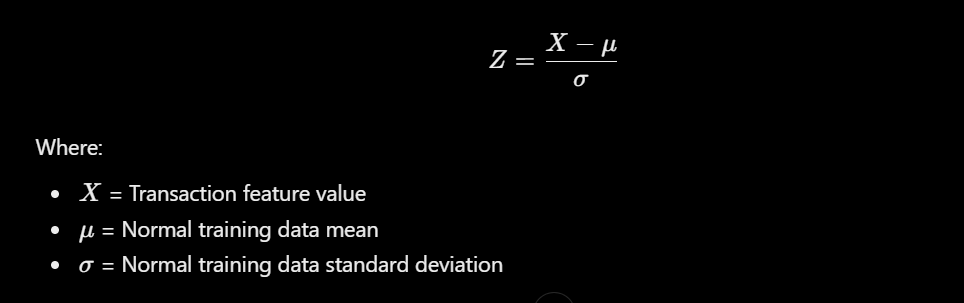

#### Based on output:
##### Feature	Transaction value	Normal mean	Z-score
##### V1	-9.3414	0.0071	-4.83
##### V2	7.4630	-0.0085	4.55
##### V9	6.8168	0.0066	6.25
##### V10	11.6609	0.0106	11.17
##### V20	4.6436	-0.0016	5.99
##### 5 unusual feature values


#####  Which features are most unusual?
##### Z-scores of transaction 45489
##### Distance from the normal training mean, measured in standard deviations.

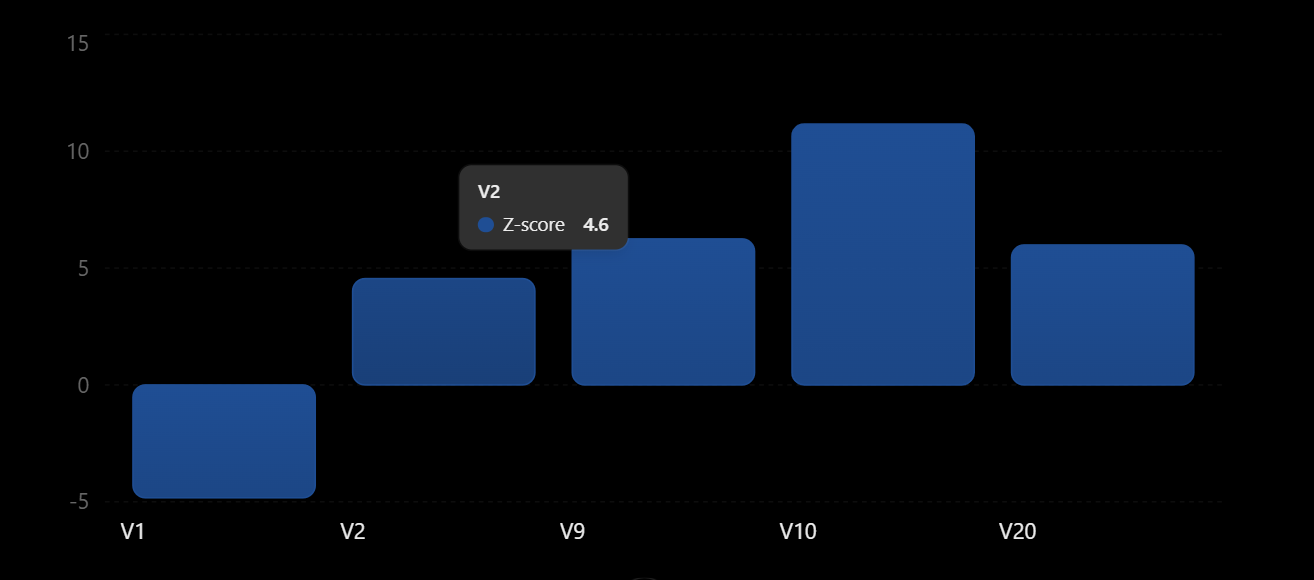











##### The most unusual feature is V10, with a Z-score of approximately 11.17.
##### This means its value is approximately 11 standard deviations above the normal training mean.
Other notable features:
- V9: approximately 6.25 standard deviations above the mean.
- V20: approximately 5.99 standard deviations above the mean.
- V1: approximately 4.83 standard deviations below the mean.
- V2: approximately 4.55 standard deviations above the mean.
- A high Z-score does not automatically mean fraud. These are PCA-transformed features, and individual Z-scores do not establish causation. Also, the minimum and maximum values in your training statistics show that some extreme values already exist among normal transactions.

In [104]:
import os
import joblib

os.makedirs("models", exist_ok=True)

# Save trained models
joblib.dump(xgb_model, "models/xgb_model.pkl")
joblib.dump(rf_model, "models/rf_model.pkl")
joblib.dump(if_model, "models/if_model.pkl")

# Save supervised model feature names
joblib.dump(
    list(X_train.columns),
    "models/supervised_feature_columns.pkl"
)

# Save Isolation Forest feature names
joblib.dump(
    list(X_train_normal.columns),
    "models/isolation_feature_columns.pkl"
)

print("All three models and feature columns saved successfully!")

All three models and feature columns saved successfully!


In [105]:
print("Supervised scaler:", scaler)

print(
    "Isolation Forest input type:",
    type(X_train_normal_scaled)
)

print(
    "Isolation Forest input shape:",
    X_train_normal_scaled.shape
)

print(
    "Supervised training shape:",
    X_train.shape
)

Supervised scaler: RobustScaler()
Isolation Forest input type: <class 'numpy.ndarray'>
Isolation Forest input shape: (199020, 30)
Supervised training shape: (199364, 30)


In [106]:
# Your RobustScaler was fitted on only two features: Time and Amount, not all 30 features.
print("Scaler feature count:", scaler.n_features_in_)

print("Scaler feature names:")
print(getattr(scaler, "feature_names_in_", "Not available"))

print("Isolation Forest features:", X_train_normal.shape[1])

Scaler feature count: 2
Scaler feature names:
['Time' 'Amount']
Isolation Forest features: 30


In [107]:
import joblib

joblib.dump(
    scaler,
    "models/supervised_scaler.pkl"
)

print("Supervised scaler saved successfully!")

Supervised scaler saved successfully!


In [108]:
import os
import joblib
from sklearn.preprocessing import StandardScaler

# Your project models directory
MODEL_DIR = r"C:\Users\HP\PROJECTS\Fraud-Detection-Using-Machine-Learning\models"

# Create directory if needed
os.makedirs(MODEL_DIR, exist_ok=True)

# Fit Isolation Forest scaler on normal training transactions
if_scaler = StandardScaler()

X_train_normal_scaled = if_scaler.fit_transform(
    X_train_normal
)

# Save scaler
joblib.dump(
    if_scaler,
    os.path.join(MODEL_DIR, "if_scaler.pkl")
)

print("Isolation Forest scaler saved successfully!")
print("Location:", MODEL_DIR)

Isolation Forest scaler saved successfully!
Location: C:\Users\HP\PROJECTS\Fraud-Detection-Using-Machine-Learning\models


In [109]:
print(os.listdir(MODEL_DIR))

['if_model.pkl', 'if_scaler.pkl', 'isolation_feature_columns.pkl', 'rf_model.pkl', 'supervised_feature_columns.pkl', 'supervised_scaler.pkl', 'xgb_model.pkl']


In [110]:
import os
import joblib

MODEL_DIR = r"C:\Users\HP\PROJECTS\Fraud-Detection-Using-Machine-Learning\models"

supervised_scaler = joblib.load(
    os.path.join(MODEL_DIR, "supervised_scaler.pkl")
)

if_scaler = joblib.load(
    os.path.join(MODEL_DIR, "if_scaler.pkl")
)

print("Supervised scaler:", type(supervised_scaler).__name__)
print("Isolation Forest scaler:", type(if_scaler).__name__)

print("\nSupervised scaler features:", supervised_scaler.n_features_in_)
print("Isolation Forest scaler features:", if_scaler.n_features_in_)

Supervised scaler: RobustScaler
Isolation Forest scaler: StandardScaler

Supervised scaler features: 2
Isolation Forest scaler features: 30


In [111]:
import sklearn
import numpy
import xgboost

print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("XGBoost:", xgboost.__version__)

Scikit-learn: 1.2.2
NumPy: 1.26.4
XGBoost: 3.2.0


In [112]:
import sys
print(sys.version)
print(sys.executable)

3.11.7 | packaged by Anaconda, Inc. | (main, Dec 15 2023, 18:05:47) [MSC v.1916 64 bit (AMD64)]
C:\Users\HP\anaconda3\python.exe


In [113]:
import pandas as pd

# Load dataset
df = pd.read_csv(r"C:\Users\HP\PROJECTS\Fraud-Detection-Using-Machine-Learning\dataset\creditcard.csv")

# Get one normal transaction
normal_sample = df[df["Class"] == 0].iloc[0]

# Get one fraudulent transaction
fraud_sample = df[df["Class"] == 1].iloc[0]

print("NORMAL TRANSACTION:")
print(normal_sample)

print("\nFRAUD TRANSACTION:")
print(fraud_sample)

NORMAL TRANSACTION:
Time        0.000000
V1         -1.359807
V2         -0.072781
V3          2.536347
V4          1.378155
V5         -0.338321
V6          0.462388
V7          0.239599
V8          0.098698
V9          0.363787
V10         0.090794
V11        -0.551600
V12        -0.617801
V13        -0.991390
V14        -0.311169
V15         1.468177
V16        -0.470401
V17         0.207971
V18         0.025791
V19         0.403993
V20         0.251412
V21        -0.018307
V22         0.277838
V23        -0.110474
V24         0.066928
V25         0.128539
V26        -0.189115
V27         0.133558
V28        -0.021053
Amount    149.620000
Class       0.000000
Name: 0, dtype: float64

FRAUD TRANSACTION:
Time      406.000000
V1         -2.312227
V2          1.951992
V3         -1.609851
V4          3.997906
V5         -0.522188
V6         -1.426545
V7         -2.537387
V8          1.391657
V9         -2.770089
V10        -2.772272
V11         3.202033
V12        -2.899907
V13        -